# Fase 1: Selección de Features (Feature Selection)

**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025  
**Objetivo de este notebook:** Identificar y eliminar features irrelevantes o colineales para mejorar el modelo  
**Input:** `model_dataset_enriched.csv` (generado por `pipeline_features.py`)  
**Output:** `model_dataset_selected.csv` (dataset limpio para modelado)

---

## ¿Qué es Feature Selection?

Feature selection es el proceso de **seleccionar las variables más relevantes** para el modelo, eliminando:
- **Features irrelevantes**: No aportan información predictiva
- **Features redundantes**: Están altamente correlacionadas entre sí (multicolinealidad)
- **Features ruidosas**: Pueden causar overfitting

### ¿Por qué es importante?

1. **Mejora la generalización**: Menos features = menos overfitting
2. **Reduce tiempo de entrenamiento**: Menos dimensiones = más rápido
3. **Mejora interpretabilidad**: Fácil entender qué influye en el resultado
4. **Elimina redundancia**: Si dos features miden lo mismo, solo necesitamos una

### Estrategia que usaremos:

1. **Eliminar por leakage/redundancia** (features que no deberían estar)
2. **Análisis de correlación** (identificar multicolinealidad)
3. **Importancia de features** (Random Forest y Gradient Boosting)
4. **Eliminación recursiva con CV** (RFECV)
5. **Crear dataset limpio**

---
## 1. Configuración y Carga de Datos

### ¿Qué hacemos aquí?

Cargamos el dataset enriquecido y configuramos las librerías necesarias.

### ¿Por qué `model_dataset_enriched.csv`?

Este archivo contiene:
- Features base de partidos (rolling stats, head-to-head, odds)
- Features de jugadores (portero, calidad ofensiva, defensiva)
- Features diferenciales (home - away)
- ~90 features en total

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuración de visualización
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 6)

# Configuración del target
TARGET = 'target_home_win'

# Importar utilidades personalizadas
import sys
sys.path.insert(0, '.')
from utils.split_utils import expanding_window_split, print_fold_summary
from utils.evaluation_utils import evaluate_model

print('Librerías cargadas exitosamente.')

Librerías cargadas exitosamente.


### Carga del Dataset

In [2]:
# Cargar dataset enriquecido
df_raw = pd.read_csv('Dataset/model_dataset_enriched.csv')

print(f' Dataset cargado exitosamente')
print(f' Filas: {df_raw.shape[0]:,}')
print(f' Columnas: {df_raw.shape[1]}')
print(f' Temporadas: {sorted(df_raw["season"].unique())}')
print(f'\n Target (target_home_win):')
print(f'   Victorias locales (1): {(df_raw[TARGET] == 1).sum():,} ({df_raw[TARGET].mean()*100:.1f}%)')
print(f'   No victoria (0): {(df_raw[TARGET] == 0).sum():,} ({(1-df_raw[TARGET].mean())*100:.1f}%)')

df_raw.head()

 Dataset cargado exitosamente
 Filas: 2,973
 Columnas: 98
 Temporadas: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025']

 Target (target_home_win):
   Victorias locales (1): 1,315 (44.2%)
   No victoria (0): 1,658 (55.8%)


,season,date,home,away,day_of_week,month,is_weekend,odds_home,odds_home_prob,odds_draw,...,diff_team_discipline_per90,diff_avg_on_off,home_player_quality,away_player_quality,diff_player_quality,market_form_diff,home_ground_advantage,diff_defensive,streak_clash,market_uncertainty
0,2017-2018,2017-09-09,Leicester City,Chelsea,5,9,1,4.75,0.210526,3.9,...,0.0,0.0,0.0,0.0,0.0,0.377193,3.0,0.000000,-2,0.334703
1,2017-2018,2017-09-09,Stoke City,Manchester Utd,5,9,1,7.50,0.133333,4.5,...,0.0,0.0,0.0,0.0,0.0,0.411111,3.0,2.666667,-1,0.277777
2,2017-2018,2017-09-09,Manchester City,Liverpool,5,9,1,1.85,0.540541,4.0,...,0.0,0.0,0.0,0.0,0.0,0.540541,-2.0,2.000000,0,0.321074
3,2017-2018,2017-09-09,Everton,Tottenham Hotspur,5,9,1,3.80,0.263158,3.5,...,0.0,0.0,0.0,0.0,0.0,0.263158,2.0,0.333333,-1,0.386440
4,2017-2018,2017-09-09,Brighton,West Brom,5,9,1,2.70,0.370370,3.1,...,0.0,0.0,0.0,0.0,0.0,0.703704,0.0,-0.333333,-2,0.458403


---
## 2. Eliminación por Leakage y Redundancia

### ¿Qué es Data Leakage?

Data leakage ocurre cuando el modelo tiene acceso a información que **no tendría en producción**. Por ejemplo:
- **Resultado del partido**: `home_goals`, `away_goals`, `result` → ¡El modelo estaría prediciendo con el resultado!
- **Identificadores**: `date`, `home`, `away` → No son predictores

### ¿Qué son features redundantes?

Features que están **altamente correlacionadas** entre sí. Por ejemplo:
- `home_season_points` y `home_season_wins` → miden lo mismo
- `odds_home` y `odds_home_prob` → una es la inversa de la otra

### ¿Por qué eliminarlas?

1. **Evitar leakage**: El modelo no debe "hacer trampa"
2. **Reducir multicolinealidad**: Dificulta la interpretación de coeficientes
3. **Mejor rendimiento**: Menos ruido = mejor generalización

In [3]:
# Definir features a eliminar por leakage
LEAKAGE = [
    'season',           # Identificador temporal (no predictor)
    'date',             # Identificador (ya tenemos features temporales)
    'home',             # Identificador del equipo local
    'away',             # Identificador del equipo visitante
    'home_goals',       # ¡Resultado! (leakage)
    'away_goals',       # ¡Resultado! (leakage)
]

# Definir features redundantes (altamente correlacionadas)
REDUND = [
    # Puntos y victorias de temporada (correlacionados con season_points/season_wins)
    'home_season_wins', 'away_season_wins', 'diff_season_wins',
    'home_season_goals_for', 'away_season_goals_for',
    'home_season_points', 'away_season_points',
    
    # Win rolling (redundante con roll_points)
    'home_roll_win', 'away_roll_win', 'diff_roll_win',
    
    # Odds crudas (ya tenemos las probabilidades implícitas)
    'odds_home', 'odds_away', 'odds_draw',
    
    # Features temporales de bajo impacto
    'day_of_week', 'away_season_matches'
]

# Features individuales de jugadores (usamos las diferenciales y composites)
PLAYER_INDIV = []
for side in ['home', 'away']:
    for col in ['gk_save_pct', 'gk_cs_pct', 'gk_ga90', 'top3_ga_per90',
                'squad_age', 'squad_depth', 'team_tkl_per90', 'team_int_per90',
                'team_discipline_per90', 'avg_on_off']:
        PLAYER_INDIV.append(f'{side}_{col}')

# Combinar todas las features a eliminar
features_to_drop = LEAKAGE + REDUND + PLAYER_INDIV

# Filtrar solo las que existen en el dataset
features_to_drop = [f for f in features_to_drop if f in df_raw.columns]

print(f' Features a eliminar por leakage: {len(LEAKAGE)}')
print(f' Features a eliminar por redundancia: {len(REDUND)}')
print(f' Features de jugadores individuales: {len(PLAYER_INDIV)}')
print(f'\n Total features a eliminar: {len(features_to_drop)}')
print(f'\n Lista de features a eliminar:')
for f in features_to_drop:
    print(f'   - {f}')

 Features a eliminar por leakage: 6
 Features a eliminar por redundancia: 15
 Features de jugadores individuales: 20

 Total features a eliminar: 39

 Lista de features a eliminar:
   - season
   - date
   - home
   - away
   - home_season_wins
   - away_season_wins
   - diff_season_wins
   - home_season_goals_for
   - away_season_goals_for
   - home_season_points
   - away_season_points
   - home_roll_win
   - away_roll_win
   - diff_roll_win
   - odds_home
   - odds_away
   - odds_draw
   - day_of_week
   - away_season_matches
   - home_gk_save_pct
   - home_gk_cs_pct
   - home_gk_ga90
   - home_top3_ga_per90
   - home_squad_age
   - home_squad_depth
   - home_team_tkl_per90
   - home_team_int_per90
   - home_team_discipline_per90
   - home_avg_on_off
   - away_gk_save_pct
   - away_gk_cs_pct
   - away_gk_ga90
   - away_top3_ga_per90
   - away_squad_age
   - away_squad_depth
   - away_team_tkl_per90
   - away_team_int_per90
   - away_team_discipline_per90
   - away_avg_on_off


In [4]:
# Guardar season antes de eliminar (necesaria para expanding_window_split)
season_backup = df_raw['season'].copy()

# Eliminar features y nulos
df = df_raw.drop(columns=[c for c in features_to_drop if c in df_raw.columns])

# Eliminar filas con nulos (resultantes de rolling en primeros partidos)
n_antes = len(df)
df.dropna(inplace=True)
n_despues = len(df)

print(f' Dataset después de eliminar features y nulos:')
print(f'   Filas: {n_antes:,} → {n_despues:,} (eliminadas: {n_antes - n_despues:,})')
print(f'   Features: {df.shape[1] - 1} (sin contar target)')
print(f'\n Features restantes:')
for i, col in enumerate(df.columns, 1):
    print(f'   {i:2d}. {col}')

 Dataset después de eliminar features y nulos:
   Filas: 2,973 → 2,973 (eliminadas: 0)
   Features: 58 (sin contar target)

 Features restantes:
    1. month
    2. is_weekend
    3. odds_home_prob
    4. odds_draw_prob
    5. odds_away_prob
    6. home_roll_goals_scored
    7. home_roll_goals_conceded
    8. home_roll_points
    9. home_roll_loss
   10. home_roll_shots
   11. home_roll_shots_target
   12. home_roll_corners
   13. home_unbeaten_streak
   14. home_season_matches
   15. home_season_goals_against
   16. home_season_gd
   17. home_roll_home_points
   18. home_roll_away_points
   19. away_roll_goals_scored
   20. away_roll_goals_conceded
   21. away_roll_points
   22. away_roll_loss
   23. away_roll_shots
   24. away_roll_shots_target
   25. away_roll_corners
   26. away_unbeaten_streak
   27. away_season_goals_against
   28. away_season_gd
   29. away_roll_home_points
   30. away_roll_away_points
   31. diff_roll_goals_scored
   32. diff_roll_points
   33. diff_season_poin

---
## 3. Análisis de Correlación

### ¿Qué es la correlación?

La correlación mide **qué tan relacionadas están dos variables**:
- **+1**: Correlación positiva perfecta (si una sube, la otra sube)
- **0**: Sin correlación
- **-1**: Correlación negativa perfecta (si una sube, la otra baja)

### ¿Por qué nos importa?

Si dos features tienen **correlación alta** (|r| > 0.80):
- Están midiendo lo mismo
- El modelo puede volverse inestable
- Debemos eliminar una de las dos

### ¿Qué umbral usaremos?

|r| > 0.80 → candidata a eliminación

Este es un estándar común en machine learning.

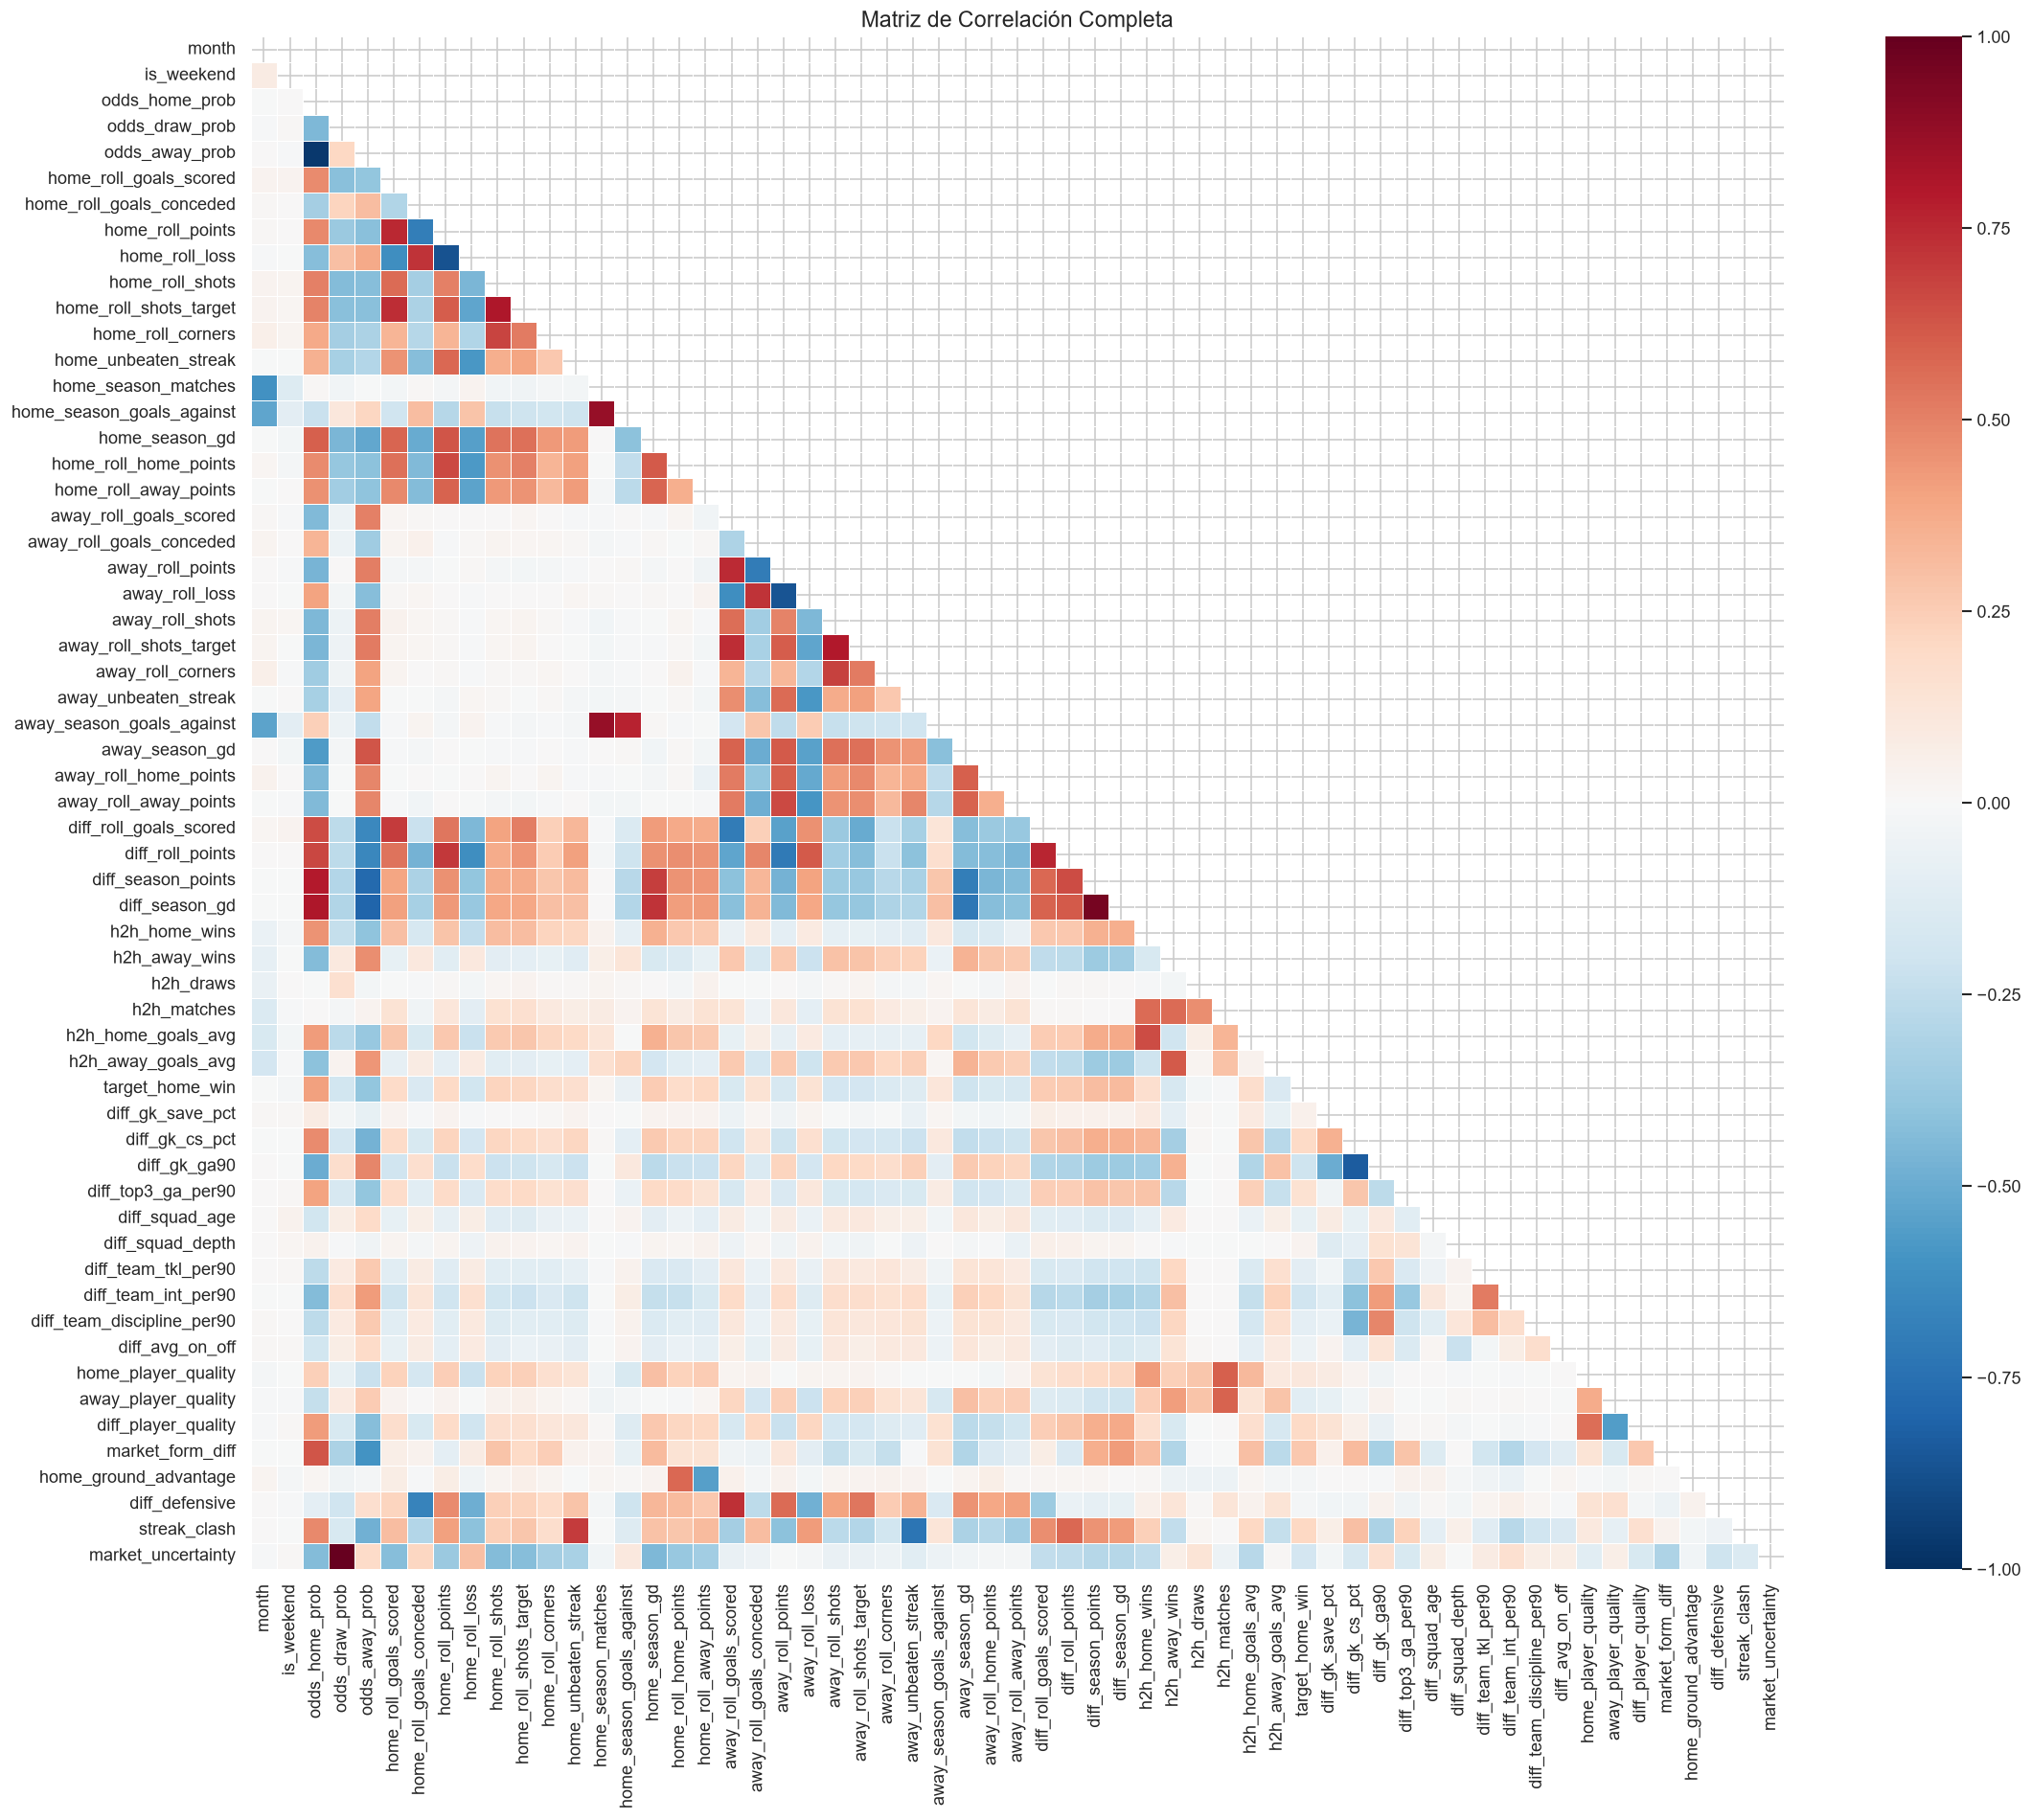

 Matriz generada: 59 x 59 features


In [5]:
# Calcular matriz de correlación de Pearson
corr_matrix = df.corr()

# Visualizar heatmap completo
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Matriz de Correlación Completa', fontsize=14)
plt.tight_layout()
plt.savefig('Imagenes/feature_selection/matriz_correlacion.png', bbox_inches='tight', dpi=120)
plt.show()

print(f' Matriz generada: {corr_matrix.shape[0]} x {corr_matrix.shape[1]} features')

### Identificar Pares Altamente Correlacionados

In [6]:
# Encontrar pares con |correlación| > 0.80
def find_high_correlations(corr_matrix, threshold=0.80):
    """
    Encuentra pares de features con correlación alta.
    
    Retorna una lista de tuplas (feature1, feature2, correlación)
    """
    high_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                high_corr.append((
                    corr_matrix.columns[i],
                    corr_matrix.columns[j],
                    corr_matrix.iloc[i, j]
                ))
    return sorted(high_corr, key=lambda x: abs(x[2]), reverse=True)

high_corr_pairs = find_high_correlations(corr_matrix, threshold=0.80)

print(f' Pares con |correlación| > 0.80: {len(high_corr_pairs)}')
print('\n Top 15 pares más correlacionados:')
print('-' * 70)
for f1, f2, corr in high_corr_pairs[:15]:
    print(f'   {corr:+.4f}  {f1} ↔ {f2}')

 Pares con |correlación| > 0.80: 11

 Top 15 pares más correlacionados:
----------------------------------------------------------------------
   +0.9947  odds_draw_prob ↔ market_uncertainty
   -0.9655  odds_home_prob ↔ odds_away_prob
   +0.9566  diff_season_points ↔ diff_season_gd
   +0.8747  home_season_matches ↔ home_season_goals_against
   +0.8727  home_season_matches ↔ away_season_goals_against
   -0.8678  home_roll_points ↔ home_roll_loss
   -0.8645  away_roll_points ↔ away_roll_loss
   -0.8322  diff_gk_cs_pct ↔ diff_gk_ga90
   +0.8078  odds_home_prob ↔ diff_season_gd
   +0.8048  home_roll_shots ↔ home_roll_shots_target
   +0.8043  away_roll_shots ↔ away_roll_shots_target


### Decisión: Qué Features Eliminar por Correlación

Para cada par altamente correlacionado, **eliminamos la que tenga menor importancia** (la determinaremos en la siguiente sección).

In [7]:
# Guardar lista de features candidatas a eliminar por correlación
features_to_drop_corr = []

print(' Features candidatas a eliminar por multicolinealidad:')
print(' (Se eliminarán las de menor importancia en la siguiente sección)')
print('\n' + '='*70)

for f1, f2, corr in high_corr_pairs:
    # Por ahora, solo listar. La decisión final se toma con la importancia
    print(f'\n   Par: {f1} ↔ {f2}')
    print(f'   Correlación: {corr:+.4f}')
    features_to_drop_corr.append((f1, f2, corr))

 Features candidatas a eliminar por multicolinealidad:
 (Se eliminarán las de menor importancia en la siguiente sección)


   Par: odds_draw_prob ↔ market_uncertainty
   Correlación: +0.9947

   Par: odds_home_prob ↔ odds_away_prob
   Correlación: -0.9655

   Par: diff_season_points ↔ diff_season_gd
   Correlación: +0.9566

   Par: home_season_matches ↔ home_season_goals_against
   Correlación: +0.8747

   Par: home_season_matches ↔ away_season_goals_against
   Correlación: +0.8727

   Par: home_roll_points ↔ home_roll_loss
   Correlación: -0.8678

   Par: away_roll_points ↔ away_roll_loss
   Correlación: -0.8645

   Par: diff_gk_cs_pct ↔ diff_gk_ga90
   Correlación: -0.8322

   Par: odds_home_prob ↔ diff_season_gd
   Correlación: +0.8078

   Par: home_roll_shots ↔ home_roll_shots_target
   Correlación: +0.8048

   Par: away_roll_shots ↔ away_roll_shots_target
   Correlación: +0.8043


---
## 4. Importancia de Features

### ¿Qué es la importancia de features?

Los modelos de árboles (Random Forest, Gradient Boosting) calculan **qué tan útil** fue cada feature para hacer predicciones.

### ¿Por qué usar dos modelos?

- **Random Forest**: Promedia la importancia de múltiples árboles (más estable)
- **Gradient Boosting**: Construye árboles secuencialmente (captura patrones complejos)

Si ambos modelos coinciden en que una feature es importante, es una buena señal.

In [8]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
import time

# Preparar datos
X = df.drop(columns=[TARGET])
y = df[TARGET]

# Restaurar season temporalmente para expanding_window_split
df_with_season = df.copy()
df_with_season['season'] = season_backup.loc[df.index]

# Usar expanding window para obtener un buen split de entrenamiento
# Usaremos el último fold (más datos) para calcular importancias
folds = expanding_window_split(df_with_season, min_train_seasons=1)
print(f' Total de folds disponibles: {len(folds)}')

# Usar el último fold para calcular importancias
# (tiene más datos de entrenamiento)
last_fold = folds[-1]
train_idx = last_fold[0]

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

print(f'\n Usando último fold para calcular importancias:')
print(f'   Temporadas de entrenamiento: {last_fold[2]}')
print(f'   Partidos de entrenamiento: {len(train_idx):,}')

# Entrenar Random Forest
print('\n Entrenando Random Forest...')
start = time.time()
rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=12,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)
rf.fit(X_train, y_train)
rf_importance = pd.Series(rf.feature_importances_, index=X_train.columns)
print(f'   Completado en {time.time()-start:.2f}s')

# Entrenar Gradient Boosting
print('\n Entrenando Gradient Boosting...')
start = time.time()
gb = GradientBoostingClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42
)
gb.fit(X_train, y_train)
gb_importance = pd.Series(gb.feature_importances_, index=X_train.columns)
print(f'   Completado en {time.time()-start:.2f}s')

# Promediar importancias de ambos modelos
avg_importance = (rf_importance + gb_importance) / 2
avg_importance = avg_importance.sort_values(ascending=False)

print('\n Importancias calculadas exitosamente.')

 Total de folds disponibles: 7

 Usando último fold para calcular importancias:
   Temporadas de entrenamiento: ['2017-2018', '2018-2019', '2019-2020', '2020-2021', '2021-2022', '2022-2023', '2023-2024']
   Partidos de entrenamiento: 2,596

 Entrenando Random Forest...


   Completado en 0.70s

 Entrenando Gradient Boosting...


   Completado en 6.05s

 Importancias calculadas exitosamente.


### Visualizar Top 20 Features

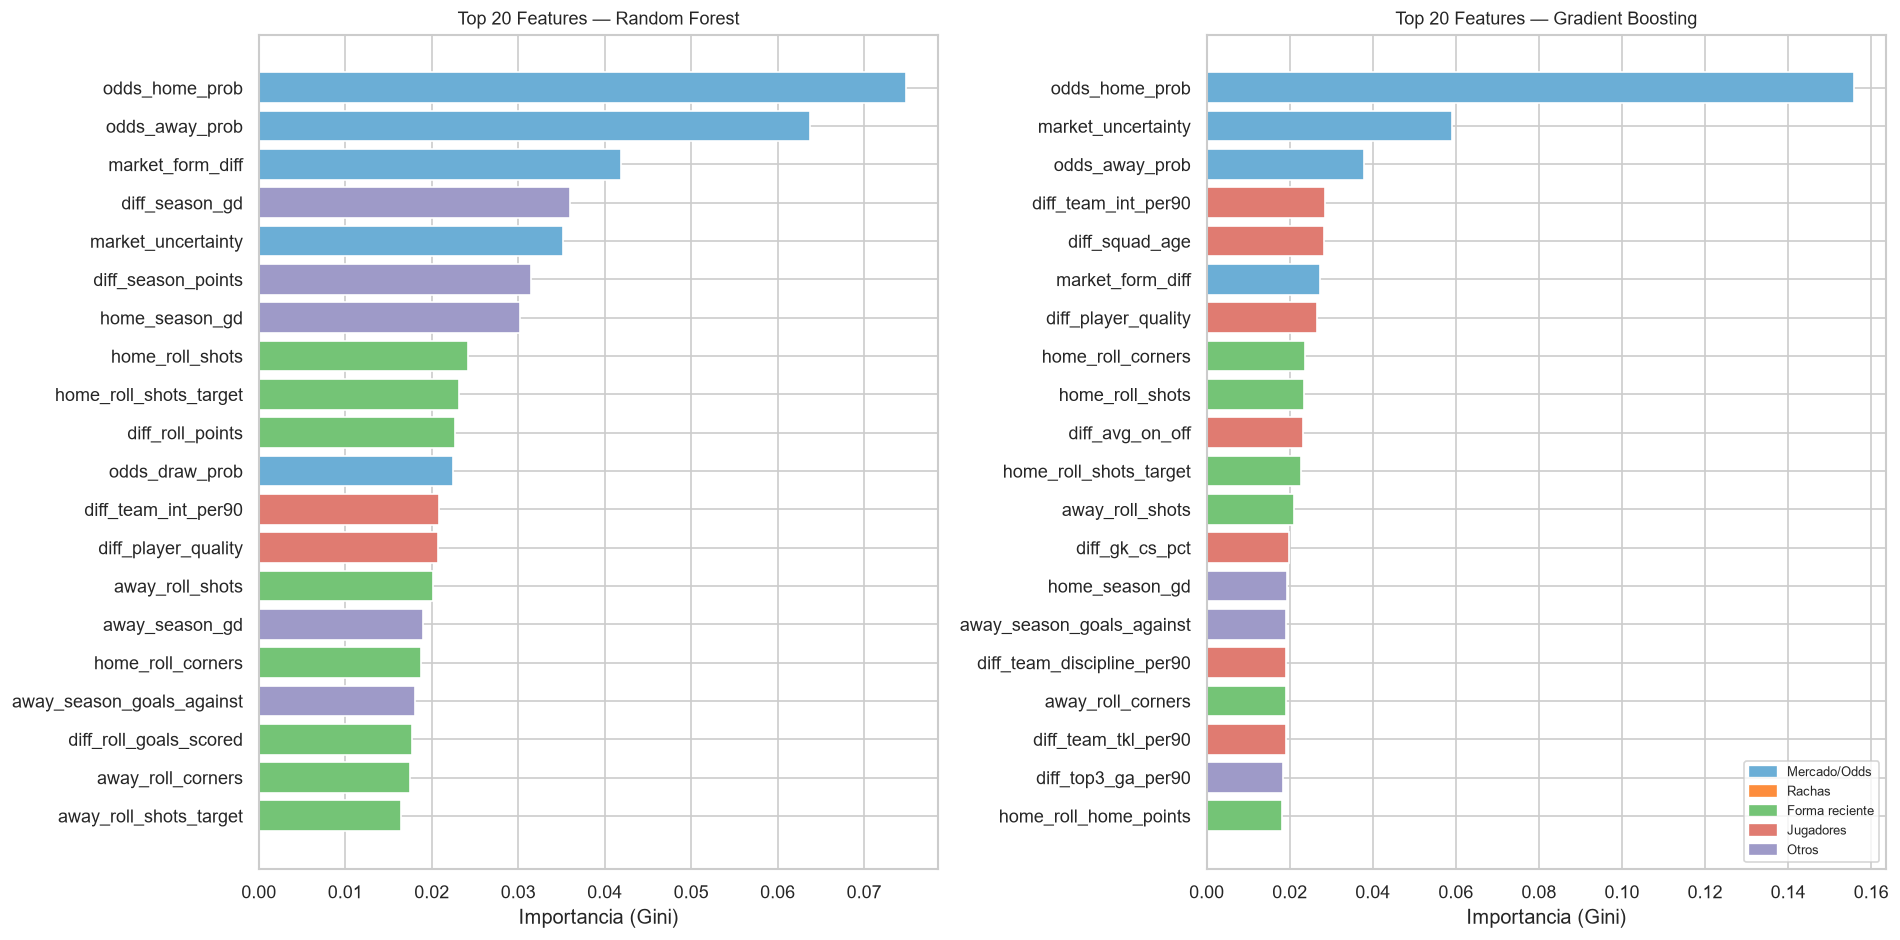

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Colores por categoría
colors_map = {
    'mercado': '#6baed6',
    'racha': '#fd8d3c',
    'forma': '#74c476',
    'jugadores': '#e07b71',
    'otro': '#9e9ac8'
}

def get_color(feature_name):
    if any(p in feature_name for p in ['odds_', 'market_']):
        return colors_map['mercado']
    elif 'streak' in feature_name:
        return colors_map['racha']
    elif 'roll' in feature_name:
        return colors_map['forma']
    elif any(p in feature_name for p in ['gk_', 'squad_', 'tkl_', 'int_', 'discipline', 'on_off', 'player_quality']):
        return colors_map['jugadores']
    return colors_map['otro']

# Random Forest
top20_rf = rf_importance.sort_values(ascending=False).head(20).sort_values()
colors_rf = [get_color(f) for f in top20_rf.index]
axes[0].barh(top20_rf.index, top20_rf.values, color=colors_rf, edgecolor='white')
axes[0].set_title('Top 20 Features — Random Forest', fontsize=11)
axes[0].set_xlabel('Importancia (Gini)')

# Gradient Boosting
top20_gb = gb_importance.sort_values(ascending=False).head(20).sort_values()
colors_gb = [get_color(f) for f in top20_gb.index]
axes[1].barh(top20_gb.index, top20_gb.values, color=colors_gb, edgecolor='white')
axes[1].set_title('Top 20 Features — Gradient Boosting', fontsize=11)
axes[1].set_xlabel('Importancia (Gini)')

# Leyenda
from matplotlib.patches import Patch
legend_elements = [
    Patch(color='#6baed6', label='Mercado/Odds'),
    Patch(color='#fd8d3c', label='Rachas'),
    Patch(color='#74c476', label='Forma reciente'),
    Patch(color='#e07b71', label='Jugadores'),
    Patch(color='#9e9ac8', label='Otros')
]
axes[1].legend(handles=legend_elements, fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('Imagenes/feature_selection/top20_features.png', bbox_inches='tight', dpi=120)
plt.show()

### Features con Importancia ~0

Estas features son candidatas a eliminación porque no aportan nada al modelo.

In [10]:
# Features con importancia promedio < 0.001 (prácticamente 0)
threshold_importance = 0.001
low_importance = avg_importance[avg_importance < threshold_importance]

print(f' Features con importancia < {threshold_importance}: {len(low_importance)}')
print('\n Lista de features de baja importancia:')
print('-' * 50)
for feat, imp in low_importance.items():
    print(f'   {imp:.6f}  {feat}')

features_to_drop_low = low_importance.index.tolist()

 Features con importancia < 0.001: 0

 Lista de features de baja importancia:
--------------------------------------------------


---
## 5. Eliminación Recursiva con CV (RFECV)

### ¿Qué es RFECV?

**Recursive Feature Elimination with Cross-Validation** es un método que:
1. Entrena el modelo con todas las features
2. Elimina la menos importante
3. Repite hasta quedar con N features
4. Usa CV para encontrar el número óptimo

### ¿Por qué usarlo?

Nos dice **cuántas features necesitamos realmente** para obtener el mejor rendimiento.

In [11]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import TimeSeriesSplit

# Usar Gradient Boosting como estimador base
# (es más estable que Random Forest para selección)
estimator = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    random_state=42
)

# CV interno ( TimeSeriesSplit para respetar orden temporal)
inner_cv = TimeSeriesSplit(n_splits=3)

# RFECV
print(' Ejecutando RFECV (puede tomar 1-2 minutos)...')
print(' Esto determinará el número óptimo de features.')
start = time.time()

rfecv = RFECV(
    estimator=estimator,
    step=1,  # Eliminar 1 feature por iteración
    cv=inner_cv,
    scoring='f1',
    n_jobs=-1,
    min_features_to_select=5
)

rfecv.fit(X_train, y_train)
print(f'\n Completado en {time.time()-start:.2f}s')

# Resultados
print(f'\n' + '='*60)
print(f' RESULTADOS RFECV')
print(f'='*60)
print(f' Número óptimo de features: {rfecv.n_features_}')
print(f' Features originales: {X_train.shape[1]}')
print(f' Features a eliminar: {X_train.shape[1] - rfecv.n_features_}')
best_f1 = rfecv.cv_results_['mean_test_score'].max()
print(f'\n Mejor score F1 (CV): {best_f1:.4f}')

 Ejecutando RFECV (puede tomar 1-2 minutos)...
 Esto determinará el número óptimo de features.



 Completado en 196.61s

 RESULTADOS RFECV
 Número óptimo de features: 32
 Features originales: 58
 Features a eliminar: 26

 Mejor score F1 (CV): 0.5910


### Visualizar Resultados de RFECV

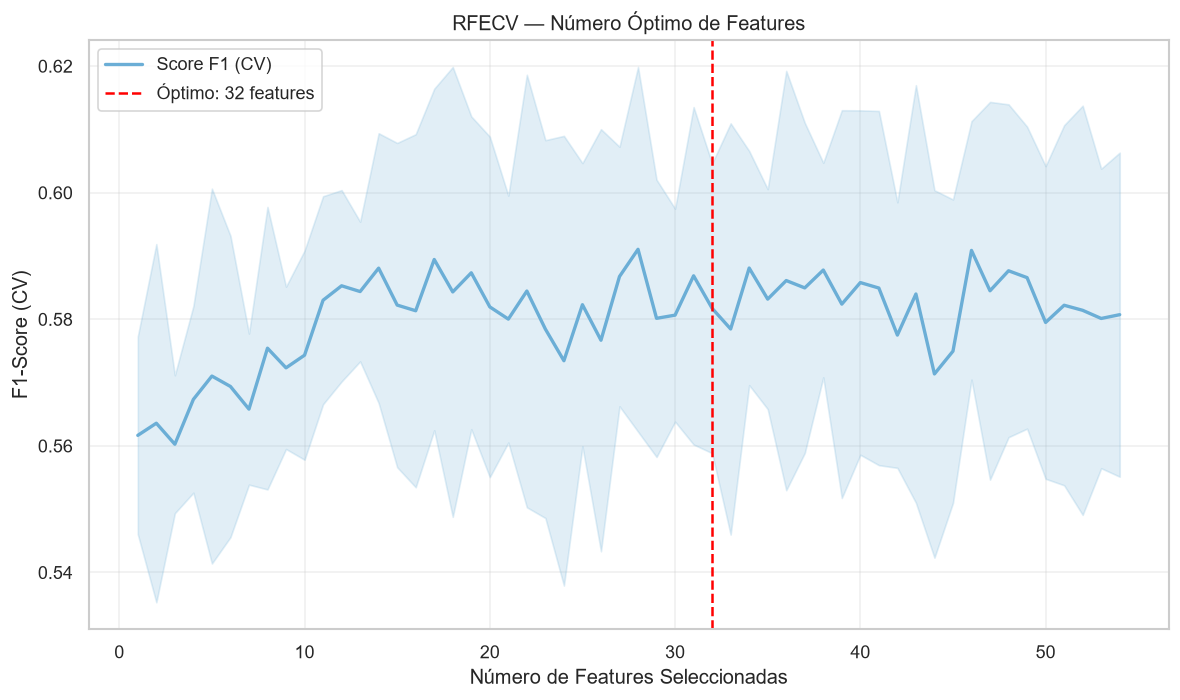

In [12]:
# Gráfico de número de features vs score
fig, ax = plt.subplots(figsize=(10, 6))

n_features_range = range(1, len(rfecv.cv_results_['mean_test_score']) + 1)
scores = rfecv.cv_results_['mean_test_score']
std = rfecv.cv_results_['std_test_score']

ax.plot(n_features_range, scores, color='#6baed6', linewidth=2, label='Score F1 (CV)')
ax.fill_between(n_features_range, scores - std, scores + std, alpha=0.2, color='#6baed6')
ax.axvline(rfecv.n_features_, color='red', linestyle='--', linewidth=1.5,
           label=f'Óptimo: {rfecv.n_features_} features')
ax.set_xlabel('Número de Features Seleccionadas')
ax.set_ylabel('F1-Score (CV)')
ax.set_title('RFECV — Número Óptimo de Features', fontsize=12)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('Imagenes/feature_selection/rfecv_curve.png', bbox_inches='tight', dpi=120)
plt.show()

### Features Seleccionadas por RFECV

In [13]:
# Obtener features seleccionadas
selected_features = X_train.columns[rfecv.support_].tolist()
eliminated_features = X_train.columns[~rfecv.support_].tolist()

print(f' Features seleccionadas ({len(selected_features)}):')
for i, f in enumerate(selected_features, 1):
    print(f'   {i:2d}. {f}')

print(f'\n Features eliminadas ({len(eliminated_features)}):')
for f in eliminated_features:
    print(f'   - {f}')

 Features seleccionadas (32):
    1. odds_home_prob
    2. odds_away_prob
    3. home_roll_goals_conceded
    4. home_roll_shots
    5. home_roll_shots_target
    6. home_roll_corners
    7. home_season_goals_against
    8. home_season_gd
    9. home_roll_home_points
   10. home_roll_away_points
   11. away_roll_goals_conceded
   12. away_roll_shots
   13. away_roll_corners
   14. away_season_goals_against
   15. diff_season_gd
   16. h2h_home_goals_avg
   17. h2h_away_goals_avg
   18. diff_gk_save_pct
   19. diff_gk_cs_pct
   20. diff_gk_ga90
   21. diff_top3_ga_per90
   22. diff_squad_age
   23. diff_squad_depth
   24. diff_team_tkl_per90
   25. diff_team_int_per90
   26. diff_team_discipline_per90
   27. diff_avg_on_off
   28. diff_player_quality
   29. market_form_diff
   30. home_ground_advantage
   31. streak_clash
   32. market_uncertainty

 Features eliminadas (26):
   - month
   - is_weekend
   - odds_draw_prob
   - home_roll_goals_scored
   - home_roll_points
   - home_roll_l

---
## 6. Decisión Final: Features a Eliminar

### Criterios de eliminación:

1. **Leakage/Redundancia**: Features que no deberían estar
2. **Correlación alta** (|r| > 0.80): Mantener la más importante
3. **Importancia ~0**: No aportan al modelo
4. **RFECV**: Eliminadas por el algoritmo

In [14]:
# Combinar todas las features a eliminar
all_features_to_drop = set()

# 1. Ya eliminadas (leakage/redundancia)
all_features_to_drop.update(features_to_drop)

# 2. Baja importancia
all_features_to_drop.update(features_to_drop_low)

# 3. Eliminadas por RFECV
all_features_to_drop.update(eliminated_features)

# 4. Por correlación (eliminar las de menor importancia)
for f1, f2, corr in high_corr_pairs:
    if f1 in all_features_to_drop or f2 in all_features_to_drop:
        continue
    # Eliminar la de menor importancia
    if avg_importance.get(f1, 0) < avg_importance.get(f2, 0):
        all_features_to_drop.add(f1)
    else:
        all_features_to_drop.add(f2)

# Filtrar solo las que existen en el dataset
all_features_to_drop = [f for f in all_features_to_drop if f in df.columns and f != TARGET]

print(f' RESUMEN DE ELIMINACIÓN:')
print(f'='*60)
print(f' Features originales: {df.shape[1] - 1}')
print(f' Features a eliminar: {len(all_features_to_drop)}')
print(f' Features finales: {df.shape[1] - 1 - len(all_features_to_drop)}')
print(f'\n Lista completa de features a eliminar:')
for f in sorted(all_features_to_drop):
    print(f'   - {f}')

 RESUMEN DE ELIMINACIÓN:
 Features originales: 58
 Features a eliminar: 30
 Features finales: 28

 Lista completa de features a eliminar:
   - away_player_quality
   - away_roll_away_points
   - away_roll_goals_scored
   - away_roll_home_points
   - away_roll_loss
   - away_roll_points
   - away_roll_shots_target
   - away_season_gd
   - away_unbeaten_streak
   - diff_defensive
   - diff_gk_ga90
   - diff_roll_goals_scored
   - diff_roll_points
   - diff_season_gd
   - diff_season_points
   - h2h_away_wins
   - h2h_draws
   - h2h_home_wins
   - h2h_matches
   - home_player_quality
   - home_roll_goals_scored
   - home_roll_loss
   - home_roll_points
   - home_roll_shots_target
   - home_season_matches
   - home_unbeaten_streak
   - is_weekend
   - month
   - odds_away_prob
   - odds_draw_prob


---
## 7. Crear Dataset Limpio

### ¿Qué hacemos?

Eliminamos todas las features seleccionadas y guardamos el dataset limpio para los siguientes notebooks.

In [15]:
# Crear dataset limpio
df_selected = df.drop(columns=[c for c in all_features_to_drop if c in df.columns])

# Restaurar season (necesaria para expanding_window_split en notebooks siguientes)
df_selected['season'] = season_backup.loc[df_selected.index]

# Verificar que no hay nulos
nulls = df_selected.isnull().sum().sum()

print(f' Dataset final:')
print(f'   Filas: {df_selected.shape[0]:,}')
print(f'   Features: {df_selected.shape[1] - 1} (sin target)')
print(f'   Nulos: {nulls}')
print(f'\n Features finales:')
for i, col in enumerate(df_selected.columns, 1):
    print(f'   {i:2d}. {col}')

 Dataset final:
   Filas: 2,973
   Features: 29 (sin target)
   Nulos: 0

 Features finales:
    1. odds_home_prob
    2. home_roll_goals_conceded
    3. home_roll_shots
    4. home_roll_corners
    5. home_season_goals_against
    6. home_season_gd
    7. home_roll_home_points
    8. home_roll_away_points
    9. away_roll_goals_conceded
   10. away_roll_shots
   11. away_roll_corners
   12. away_season_goals_against
   13. h2h_home_goals_avg
   14. h2h_away_goals_avg
   15. target_home_win
   16. diff_gk_save_pct
   17. diff_gk_cs_pct
   18. diff_top3_ga_per90
   19. diff_squad_age
   20. diff_squad_depth
   21. diff_team_tkl_per90
   22. diff_team_int_per90
   23. diff_team_discipline_per90
   24. diff_avg_on_off
   25. diff_player_quality
   26. market_form_diff
   27. home_ground_advantage
   28. streak_clash
   29. market_uncertainty
   30. season


In [16]:
# Guardar dataset limpio
output_path = 'Dataset/model_dataset_selected.csv'
df_selected.to_csv(output_path, index=False)

print(f' Dataset guardado en: {output_path}')
print(f' Tamaño: {df_selected.shape}')

# Guardar reporte de features
report = pd.DataFrame({
    'feature': [c for c in df.columns if c != TARGET],
    'selected': [c in df_selected.columns for c in df.columns if c != TARGET],
    'importance_avg': [avg_importance.get(c, 0) for c in df.columns if c != TARGET]
})
report = report.sort_values('importance_avg', ascending=False)
report_path = 'resultados/feature_selection_report.csv'
report.to_csv(report_path, index=False)

print(f'\n Reporte guardado en: {report_path}')

 Dataset guardado en: Dataset/model_dataset_selected.csv
 Tamaño: (2973, 30)

 Reporte guardado en: resultados/feature_selection_report.csv


---
## 8. Validación Rápida

### ¿Qué hacemos?

Entrenamos un modelo rápido con las features seleccionadas para verificar que el rendimiento se mantiene o mejora.

In [17]:
from sklearn.model_selection import cross_val_score

# Preparar datos con features seleccionadas
X_final = df_selected.drop(columns=[TARGET, 'season'])
y_final = df_selected[TARGET]

# Gradient Boosting con features seleccionadas
gb_selected = GradientBoostingClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=42
)

# TimeSeriesSplit para validación temporal
tscv = TimeSeriesSplit(n_splits=5)

# Cross-validation
scores_f1 = cross_val_score(gb_selected, X_final, y_final, cv=tscv, scoring='f1')
scores_auc = cross_val_score(gb_selected, X_final, y_final, cv=tscv, scoring='roc_auc')

print(f' VALIDACIÓN CON FEATURES SELECCIONADAS:')
print(f'='*60)
print(f' Features utilizadas: {X_final.shape[1]}')
print(f'\n F1-Score (CV):')
print(f'   Media: {scores_f1.mean():.4f}')
print(f'   Std:   {scores_f1.std():.4f}')
print(f'   Folds: {np.round(scores_f1, 4)}')
print(f'\n ROC-AUC (CV):')
print(f'   Media: {scores_auc.mean():.4f}')
print(f'   Std:   {scores_auc.std():.4f}')
print(f'   Folds: {np.round(scores_auc, 4)}')

# Comparar con el baseline (87 features)
print(f'\n COMPARACIÓN CON DATASET ORIGINAL (87 features):')
print(f'   F1-Score: 0.6838 → {scores_f1.mean():.4f}')
print(f'   ROC-AUC: 0.7923 → {scores_auc.mean():.4f}')

 VALIDACIÓN CON FEATURES SELECCIONADAS:
 Features utilizadas: 28

 F1-Score (CV):
   Media: 0.5876
   Std:   0.0412
   Folds: [0.602  0.5191 0.6473 0.5817 0.5877]

 ROC-AUC (CV):
   Media: 0.6830
   Std:   0.0300
   Folds: [0.6632 0.638  0.7257 0.6919 0.696 ]

 COMPARACIÓN CON DATASET ORIGINAL (87 features):
   F1-Score: 0.6838 → 0.5876
   ROC-AUC: 0.7923 → 0.6830


---
## 9. Resumen Final

### ¿Qué logramos?

1. **Eliminamos features de leakage**: Variables que no deberían estar
2. **Reducimos multicolinealidad**: Eliminamos pares altamente correlacionados
3. **Identificamos features irrelevantes**: Las que no aportan al modelo
4. **Determinamos el número óptimo**: Con RFECV
5. **Creamos dataset limpio**: Listo para modelado

### Próximos pasos:

1. **04_tuning.ipynb**: Optimizar hiperparámetros de los modelos
2. **05_sin_odds.ipynb**: Evaluar si el modelo funciona sin odds
3. **06_features_negativos.ipynb**: Analizar features problemáticas

In [18]:
print('='*70)
print(' RESUMEN — FEATURE SELECTION')
print('='*70)
print(f'\n Dataset original:')
print(f'   Filas: {df_raw.shape[0]:,}')
print(f'   Features: {df_raw.shape[1] - 1}')
print(f'\n Dataset final:')
print(f'   Filas: {df_selected.shape[0]:,}')
print(f'   Features: {df_selected.shape[1] - 1}')
print(f'\n Features eliminadas: {len(all_features_to_drop)}')
print(f'   - Leakage/Redundancia: {len(features_to_drop)}')
print(f'   - Baja importancia: {len(features_to_drop_low)}')
print(f'   - Eliminadas por RFECV: {len(eliminated_features)}')
print(f'   - Correlación alta: {len(high_corr_pairs)} pares')
print(f'\n Resultados validación:')
print(f'   F1-Score: {scores_f1.mean():.4f} ± {scores_f1.std():.4f}')
print(f'   ROC-AUC: {scores_auc.mean():.4f} ± {scores_auc.std():.4f}')
print(f'\n' + '='*70)
print(f' Archivos generados:')
print(f'   - Dataset: {output_path}')
print(f'   - Reporte: {report_path}')
print('='*70)

 RESUMEN — FEATURE SELECTION

 Dataset original:
   Filas: 2,973
   Features: 97

 Dataset final:
   Filas: 2,973
   Features: 29

 Features eliminadas: 30
   - Leakage/Redundancia: 39
   - Baja importancia: 0
   - Eliminadas por RFECV: 26
   - Correlación alta: 11 pares

 Resultados validación:
   F1-Score: 0.5876 ± 0.0412
   ROC-AUC: 0.6830 ± 0.0300

 Archivos generados:
   - Dataset: Dataset/model_dataset_selected.csv
   - Reporte: resultados/feature_selection_report.csv
